# 04 · Clasificación supervisada y priorización top-K (Paso 08)

**Pregunta:** ¿qué barrios estarán entre los 10 con más siniestros con víctimas el mes siguiente?

**Protocolo:** [docs/experimental_protocol.md](../docs/experimental_protocol.md), incluida la aclaración previa sobre la métrica de selección (sección 11). **Informe y dictamen:** [docs/classification_report.md](../docs/classification_report.md).

| Elemento | Definición |
|---|---|
| Objetivo | `top10_target`: exactamente 10 positivos por mes (20,8 %), con desempate R0 |
| Particiones | V2022, V2023 y V2024 (validación); 2025 (test congelado), con las mismas filas que la regresión |
| Métrica de selección | Precision@10 esperada invariante a empates, promediada en los *folds*; desempate por PR-AUC |
| Otras métricas | PR-AUC, ROC-AUC, Brier y confiabilidad; *precision*, *recall*, F1 y matriz de confusión con el umbral elegido en validación; Precision@10 con R0; plazas inciertas |
| Criterio de mejora | ΔP@10 ≥ 0,02 (media y al menos 2 de 3 *folds*) con el intervalo pareado de desempate excluyendo el 0. En test: IC por bloques de ΔP@10 > 0 y el intervalo pareado excluyendo el 0 |
| Candidatos | Regresión logística L2 (16), *random forest* (24) y HGB (16). Total: 56 (`src/classification.py`). SMOTE no aplica (prevalencia del 20,8 %) |

§1–§3 usan solo el desarrollo y **congelan** la selección y el umbral. La sección 4 presenta la evaluación principal de 2025 con gap = 0. La sección 6 reutiliza 2025 como sensibilidad exploratoria y conserva la selección congelada.

### Guía para el lector

**La pregunta, en una frase.** Si cada mes solo se pudiera priorizar 10 de los 48 barrios, ¿un modelo acierta mejor que el historial cuáles estarán entre los 10 con más siniestros con víctimas el mes siguiente?

**Por qué importa.** Es la forma más cercana a una decisión real: elegir dónde concentrar esfuerzos con recursos limitados. El objetivo es relativo (los 10 más altos del mes), así que no lo afectan los cambios generales de nivel, como la pandemia.

**Cómo se mide.** Con la **Precision@10**: de los 10 barrios elegidos, qué proporción estuvo efectivamente entre los 10 con más hechos. Por ejemplo, 0,80 significa 8 aciertos de 10. Se usa su versión «esperada», que no depende de cómo se desempatan los barrios con igual cantidad de hechos.

**Cómo se procede.**
1. Referencias simples (§1).
2. 56 configuraciones de tres familias de modelos, evaluadas en 2022–2024 (§2).
3. Elección y congelamiento solo con la validación (§3). Para declarar una mejora se exigen al menos 0,02 de Precision@10 adicional (2 aciertos más cada 100 elecciones), ganar en 2 de 3 años y que la ventaja no dependa del desempate.
4. Una única evaluación en 2025 (§4), seguida de la interpretación del modelo (§5) y de una sensibilidad exploratoria a la demora de publicación (§6).

**Resultado principal.** Gana una regresión logística regularizada. En 2025 acierta 0,808 frente a 0,792 del promedio de 12 meses: **2 aciertos más en 120 elecciones** (10 por mes durante 12 meses). El intervalo de confianza incluye el 0 (entre −0,017 y +0,058), así que **la mejora no se confirma**. Frente a repetir el top 10 del último mes (0,746 en la misma métrica), la ventaja sí es clara. Las probabilidades están razonablemente calibradas en 2025, un solo año, con sobreestimación en los barrios de borde.

**Por qué ocurre.** El modelo se apoya casi por completo en el historial del barrio (75 % de la importancia). Cinco barrios están en el top 10 casi todos los meses, y la disputa real se da por las 5 plazas restantes. Allí el modelo acierta 65 % y el historial 62 %.

### Glosario de este notebook

| Término | Significado |
|---|---|
| **`top10_target`** | 1 si el barrio está entre los 10 con más hechos del mes; exactamente 10 positivos por mes (20,8 % de los barrios). |
| **P@10 con R0; P@10 esperada** | Aciertos entre los 10 elegidos, desempatando con el sorteo R0; promedio de aciertos considerando todos los desempates posibles. La segunda es la métrica de selección. |
| **PR-AUC; ROC-AUC** | Calidad del ordenamiento de todos los barrios, no solo de los 10 primeros (1 = perfecto). |
| **Brier; calibración** | Error de las probabilidades; si un 30 % pronosticado se cumple alrededor del 30 % de las veces, el modelo está bien calibrado. |
| **Umbral (0,46); *precision*, *recall*, F1** | Probabilidad a partir de la cual se dice «estará en el top 10»; proporción de aciertos entre los señalados, proporción de positivos detectados y su promedio armónico. |
| **Logística L2 (C)** | Regresión logística con penalización; un C más chico implica una penalización más fuerte. |
| ***Random forest*; HGB** | Modelos de árboles de decisión. |
| **Ponderación de clases; SMOTE** | Técnicas para clases poco frecuentes. No hacen falta: hay exactamente 20,8 % de positivos. |
| **Núcleo persistente; plazas inciertas** | Barrios que casi siempre están en el top 10; las plazas restantes, donde se juega la diferencia. |
| **Intervalo pareado de desempate** | Variación de la ventaja al repetir el desempate con 500 semillas. |
| **IC por bloques** | Incertidumbre entre meses (bloques de 3 meses). Es distinta de la anterior y es la que decide si la mejora es concluyente. |
| **SHAP** | Cuánto contribuye cada variable a cada predicción. Describe el modelo; no implica causas. |
| **H4** | Hipótesis de la propuesta: un modelo mejora al historial en la priorización top-K. |

## 0. Datos y particiones

> **Qué hace la celda siguiente.** Construye la misma tabla de variables y las mismas particiones que la regresión, de modo que ambas tareas se evalúen sobre las mismas filas y fechas.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_fscore_support, confusion_matrix
from sklearn.calibration import calibration_curve
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src import features as F, regression as R, classification as Cl
from src.evaluation import block_bootstrap_ci
warnings.filterwarnings("ignore")
FIG, TAB = ROOT / "reports" / "figures" / "04_classification", ROOT / "reports" / "tables" / "04_classification"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10})
panel = F.load_panel(); nbrs = F.queen_neighbors()
XG = {g: R.add_log_features(F.build_features(panel, nbrs, h=1, gap=g)) for g in (0, 1)}
X = XG[0]; folds = F.temporal_folds(X); tr_fin, te_fin = F.final_split(X)
M = {"configs_probadas": len(Cl.grid())}
print({fo["fold"]: (fo["train_desde"], fo["train_hasta"], int(fo["train"].sum()), int(fo["val"].sum())) for fo in folds}, "| final", int(tr_fin.sum()), int(te_fin.sum()))

{'V2022': ('2020-01', '2021-12', 1152, 576), 'V2023': ('2020-01', '2022-12', 1728, 576), 'V2024': ('2020-01', '2023-12', 2304, 576)} | final 2880 576


> **Qué hace la celda siguiente.** Define las métricas de cada año de validación: Precision@10 esperada y con R0, PR-AUC, ROC-AUC y Brier (este último solo cuando hay probabilidades).

In [2]:
def fold_metrics(df, score, prob=None):
    out = {"P@10_esperada": float(Cl.expected_precision_at_k(df, score).mean()),
           "P@10_R0": float(Cl.precision_at_k(df, score).mean()),
           "PR_AUC": float(average_precision_score(df["top10_target"], df[score])),
           "ROC_AUC": float(roc_auc_score(df["top10_target"], df[score]))}
    if prob is not None:
        out["Brier"] = float(brier_score_loss(df["top10_target"], df[prob]))
    return out

## 1. Baselines de ranking en validación

> **Qué hace la celda siguiente.** Evalúa las dos referencias de ranking: repetir el último mes y el promedio de 12 meses. **Qué mirar en la salida:** el promedio de 12 meses acierta 0,779 en promedio; es la vara a superar.

In [3]:
rows = []
for fo in folds:
    v = X.loc[fo["val"]]
    for b, col in Cl.BASELINES.items():
        rows.append({"modelo": f"baseline:{b}", "fold": fo["fold"], **fold_metrics(v, col)})
base_val = pd.DataFrame(rows)
bv = base_val.pivot(index="modelo", columns="fold", values="P@10_esperada"); bv["media"] = bv.mean(axis=1)
best_base = bv["media"].idxmax(); M["mejor_baseline"] = best_base
base_val.to_csv(TAB / "baselines_validacion.csv", index=False)
display(base_val.groupby("modelo").mean(numeric_only=True).round(4)); print("Mejor baseline:", best_base)

,P@10_esperada,P@10_R0,PR_AUC,ROC_AUC
modelo,,,,
baseline:media12,0.7792,0.7806,0.8771,0.9562
baseline:persistencia,0.7275,0.7361,0.8003,0.9247


Mejor baseline: baseline:media12


## 2. Búsqueda en grilla

> **Qué hace la celda siguiente.** Entrena las 56 configuraciones en los tres años de validación (tarda unos 2 minutos) y las ordena por Precision@10 esperada. **Qué mirar en la salida:** encabezan las regresiones logísticas, con diferencias de milésimas entre ellas.

In [4]:
res, VP = [], {}
t0 = time.time()
for kind, params in Cl.grid():
    name = Cl.config_name(kind, params)
    for fo in folds:
        trm = R.train_mask_excluding_pandemia(X, fo["train"], params["excluir_pandemia"])
        m = Cl.make_model(kind, params).fit(X.loc[trm], X.loc[trm, "top10_target"].astype(int))
        v = X.loc[fo["val"], ["barrio", "mes_objetivo", "y_target", "top10_target"]].copy()
        v["p"] = m.predict_proba(X.loc[fo["val"]])[:, 1]
        VP[(name, fo["fold"])] = v
        res.append({"modelo": name, "familia": kind, "fold": fo["fold"], **fold_metrics(v, "p", "p")})
grid_res = pd.DataFrame(res); M["tiempo_grilla_s"] = round(time.time() - t0, 1)
summ = grid_res.groupby(["familia", "modelo"]).agg(P10e_media=("P@10_esperada", "mean"), PR_AUC_media=("PR_AUC", "mean"),
                                                    Brier_media=("Brier", "mean")).reset_index()
summ = summ.merge(grid_res.pivot(index="modelo", columns="fold", values="P@10_esperada"), left_on="modelo", right_index=True)
summ = summ.sort_values(["P10e_media", "PR_AUC_media"], ascending=False); summ.to_csv(TAB / "grilla_validacion.csv", index=False)
print(f"{len(summ)} configuraciones × 3 folds en {M['tiempo_grilla_s']} s"); summ.head(10).round(4)

56 configuraciones × 3 folds en 127.5 s


,familia,modelo,P10e_media,PR_AUC_media,Brier_media,V2022,V2023,V2024
17,logit,"logit|C=0.01,class_weight=None,excluir_pandemi...",0.7949,0.8775,0.0659,0.7694,0.8292,0.7861
21,logit,"logit|C=0.1,class_weight=None,excluir_pandemia...",0.7935,0.8732,0.0644,0.7778,0.8167,0.7861
19,logit,"logit|C=0.01,class_weight=balanced,excluir_pan...",0.7921,0.8772,0.0951,0.7611,0.8292,0.7861
43,rf,"rf|max_depth=8,min_samples_leaf=20,class_weigh...",0.7894,0.8719,0.0893,0.7361,0.8375,0.7944
51,rf,"rf|max_depth=None,min_samples_leaf=20,class_we...",0.7894,0.8719,0.0893,0.7361,0.8375,0.7944
39,rf,"rf|max_depth=4,min_samples_leaf=5,class_weight...",0.7894,0.8656,0.0866,0.7444,0.8292,0.7944
16,logit,"logit|C=0.01,class_weight=None,excluir_pandemi...",0.7894,0.8796,0.0646,0.7528,0.8292,0.7861
18,logit,"logit|C=0.01,class_weight=balanced,excluir_pan...",0.7894,0.8789,0.0944,0.7611,0.8208,0.7861
38,rf,"rf|max_depth=4,min_samples_leaf=5,class_weight...",0.7894,0.8736,0.0946,0.7444,0.8375,0.7861
42,rf,"rf|max_depth=8,min_samples_leaf=20,class_weigh...",0.7866,0.8781,0.0902,0.7361,0.8292,0.7944


## 3. Selección, umbral y criterio de mejora (solo validación)

> **Qué hace la celda siguiente.** Aplica la regla de selección, fija el umbral de decisión con la validación y guarda todo en `seleccion_congelada.json` antes de evaluar 2025.

In [5]:
best_by_fam = summ.drop_duplicates("familia").set_index("familia")
sel = summ.iloc[0]; kind_sel, params_sel = next((k, p) for k, p in Cl.grid() if Cl.config_name(k, p) == sel["modelo"])
bfold = bv.loc[best_base, ["V2022", "V2023", "V2024"]]
# Validación agrupada (36 meses) del seleccionado, con la puntuación del baseline en las mismas filas
pooled = pd.concat([VP[(sel["modelo"], fo["fold"])].assign(fold=fo["fold"]) for fo in folds])
pooled["base"] = X.loc[np.concatenate([np.where(fo["val"])[0] for fo in folds]), Cl.BASELINES[best_base.split(":")[1]]].to_numpy()
tie_val = Cl.paired_tie_interval(pooled, "p", "base", seeds=500)
crit = []
for fam, r in best_by_fam.iterrows():
    d = r["P10e_media"] - bv.loc[best_base, "media"]; wins = int(sum(r[f] - bfold[f] >= .02 for f in ["V2022", "V2023", "V2024"]))
    crit.append({"familia": fam, "modelo": r["modelo"], "P10e_media": r["P10e_media"], "delta_vs_mejor_baseline": d, "folds_con_delta_>=0.02": wins})
crit = pd.DataFrame(crit).sort_values("P10e_media", ascending=False)
d_sel = sel["P10e_media"] - bv.loc[best_base, "media"]; w_sel = int(sum(sel[f] - bfold[f] >= .02 for f in ["V2022", "V2023", "V2024"]))
cumple = bool(d_sel >= .02 and w_sel >= 2 and tie_val["p2.5"] > 0)
# Umbral de F1 con las predicciones de validación agrupadas
grid_t = np.linspace(.05, .95, 91)
f1s = [precision_recall_fscore_support(pooled["top10_target"], pooled["p"] >= t, average="binary", zero_division=0)[2] for t in grid_t]
thr = float(grid_t[int(np.argmax(f1s))])
frozen = {"modelo_seleccionado": sel["modelo"], "familia": kind_sel, "params": params_sel, "P10e_validacion_media": float(sel["P10e_media"]),
          "mejor_baseline": best_base, "P10e_baseline_validacion_media": float(bv.loc[best_base, "media"]), "delta": float(d_sel),
          "folds_con_delta_>=0.02": w_sel, "intervalo_pareado_validacion": tie_val, "cumple_criterio_validacion": cumple,
          "umbral_F1": thr, "F1_validacion_en_umbral": float(max(f1s)),
          "mejores_por_familia": {fam: r["modelo"] for fam, r in best_by_fam.iterrows()},
          "congelado_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"), "configs_probadas": M["configs_probadas"]}
(TAB / "seleccion_congelada.json").write_text(json.dumps(frozen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
M["seleccion"] = frozen; crit.to_csv(TAB / "seleccion_criterio.csv", index=False)
display(crit.round(4)); print(json.dumps({k: frozen[k] for k in ["modelo_seleccionado", "delta", "folds_con_delta_>=0.02", "intervalo_pareado_validacion", "cumple_criterio_validacion", "umbral_F1"]}, indent=1, ensure_ascii=False, default=str))

,familia,modelo,P10e_media,delta_vs_mejor_baseline,folds_con_delta_>=0.02
0,logit,"logit|C=0.01,class_weight=None,excluir_pandemi...",0.7949,0.0157,1
1,rf,"rf|max_depth=8,min_samples_leaf=20,class_weigh...",0.7894,0.0102,1
2,hgb,"hgb|max_leaf_nodes=7,min_samples_leaf=20,class...",0.7762,-0.0030,0


{
 "modelo_seleccionado": "logit|C=0.01,class_weight=None,excluir_pandemia=True",
 "delta": 0.0157407407407405,
 "folds_con_delta_>=0.02": 1,
 "intervalo_pareado_validacion": {
  "mediana": 0.016666666666666663,
  "p2.5": 0.013888888888888886,
  "p97.5": 0.019444444444444445,
  "excluye_0": true,
  "semillas": 500
 },
 "cumple_criterio_validacion": false,
 "umbral_F1": 0.4599999999999999
}


> **Qué hace la celda siguiente.** Separa el núcleo de barrios que casi siempre están en el top 10, definido solo con datos de entrenamiento, y mide cuánto acierta cada estrategia en las plazas restantes, donde está la incertidumbre real.

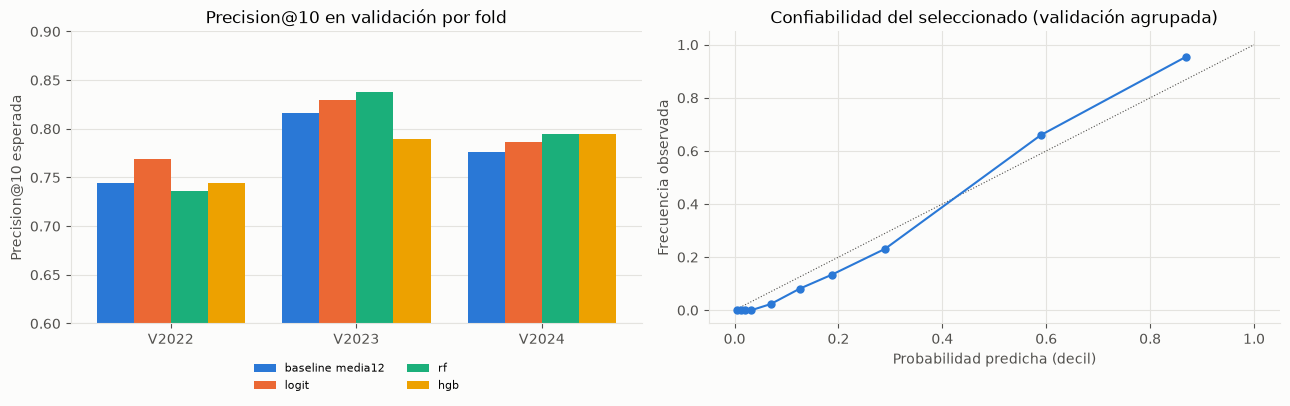

,fold,nucleo,precision_modelo,precision_baseline,sel_fuera_nucleo_modelo,sel_fuera_nucleo_baseline
0,V2022,3,0.679,0.643,84,84
1,V2023,5,0.700,0.683,60,60
2,V2024,5,0.617,0.583,60,60


In [6]:
# Plazas inciertas en validación: núcleo persistente definido con el entrenamiento de cada fold
rows = []
for fo in folds:
    core = Cl.core_from_training(X.loc[fo["train"]])
    v = VP[(sel["modelo"], fo["fold"])].copy(); v["base"] = X.loc[fo["val"], Cl.BASELINES[best_base.split(":")[1]]].to_numpy()
    a, b = Cl.uncertain_slots_precision(v, "p", core), Cl.uncertain_slots_precision(v, "base", core)
    rows.append({"fold": fo["fold"], "nucleo": len(core), "precision_modelo": a["precision"], "precision_baseline": b["precision"],
                 "sel_fuera_nucleo_modelo": a["seleccionados_fuera_del_nucleo"], "sel_fuera_nucleo_baseline": b["seleccionados_fuera_del_nucleo"]})
inc_val = pd.DataFrame(rows); inc_val.to_csv(TAB / "plazas_inciertas_validacion.csv", index=False); M["plazas_inciertas_validacion"] = inc_val.round(4).to_dict(orient="records")
# Confiabilidad en validación
pt, pp = calibration_curve(pooled["top10_target"], pooled["p"], n_bins=10, strategy="quantile")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
show = [best_base] + list(best_by_fam["modelo"])
pv = pd.concat([base_val, grid_res]).query("modelo in @show").pivot(index="modelo", columns="fold", values="P@10_esperada").loc[show]
x = np.arange(3); w = .8 / len(show)
for i, mdl in enumerate(show):
    axes[0].bar(x + i * w - .4 + w / 2, pv.loc[mdl], width=w, color=CAT[i], label=mdl.split("|")[0].replace("baseline:", "baseline "))
axes[0].set_xticks(x, pv.columns); axes[0].set_ylim(.6, .9); axes[0].set_ylabel("Precision@10 esperada"); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Precision@10 en validación por fold"); axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.1))
axes[1].plot([0, 1], [0, 1], color=INK2, lw=.8, ls=":"); axes[1].plot(pp, pt, color=CAT[0], marker="o", ms=5)
axes[1].set_xlabel("Probabilidad predicha (decil)"); axes[1].set_ylabel("Frecuencia observada"); axes[1].set_title("Confiabilidad del seleccionado (validación agrupada)")
fig.tight_layout(); fig.savefig(FIG / "validacion_p10_calibracion.png", dpi=150); plt.show()
inc_val.round(3)

**Lectura (3, validación).**
- **Umbral histórico de F1.** Se congeló 0,46 (F1 = 0,7983), el máximo en una grilla de 91 cortes de 0,05 a 0,95 en las predicciones agrupadas de V2022–V2024. La auditoría posterior encontró un máximo de 0,8006 en 0,444245 al evaluar todos los cortes distintos de validación. Las métricas publicadas de 2025 usan 0,46; el ranking top-10 se obtiene directamente de los puntajes.
- **Baseline.** El mejor ranking de referencia es la **media de 12 meses** (P@10 esperada 0,779; PR-AUC 0,877), por encima de la persistencia (0,728).
- **Selección.** Gana la **regresión logística L2 (C = 0,01), sin ponderación de clases y sin meses de pandemia en el entrenamiento**, con P@10 esperada de 0,795. La ventaja frente al baseline es de +0,016. Como se eligió la mejor de 56 configuraciones con diferencias de milésimas, esa ventaja de validación es una estimación optimista (efecto del ganador; revisión independiente, R8). Es **robusta al desempate** (intervalo pareado de 500 semillas: [0,014; 0,019]), pero **queda por debajo del umbral de relevancia** de 0,02 y solo alcanza ese umbral en 1 de 3 *folds*. **No cumple el criterio de mejora.**
- **Cuántas configuraciones superan el umbral.** Ninguna de las 56.
- **Otras familias.** El *random forest* (0,789) y el HGB (0,776) quedan por detrás.
- **Ponderación de clases.** Empeora la calibración (Brier de alrededor de 0,095, frente a 0,066) sin mejorar el ranking. Con una prevalencia fija del 20,8 %, SMOTE no es pertinente.
- **Plazas inciertas.** Fuera del núcleo persistente (3 a 5 barrios según el *fold*), el modelo acierta entre 62 % y 70 % de sus selecciones, frente a 58 %–68 % del baseline: una ventaja de 2 a 4 puntos en los tres *folds*.
- **Calibración.** Es razonable, con leve sobreestimación en las probabilidades intermedias.

## 4. Evaluación principal en 2025 (gap = 0)

Se usa la selección y el umbral congelados. También se informan, **sin uso para decidir**, el mejor modelo de cada familia y los baselines.

> **Qué hace la celda siguiente.** Lee la selección congelada, la reentrena con todo 2020–2024 y pronostica 2025 mes a mes. También calcula las referencias, solo para comparar.

In [7]:
frozen = json.loads((TAB / "seleccion_congelada.json").read_text(encoding="utf-8"))
cfgs = {n: next((k, p) for k, p in Cl.grid() if Cl.config_name(k, p) == n) for n in sorted(set(frozen["mejores_por_familia"].values()))}
T = X.loc[te_fin, ["barrio", "mes_objetivo", "y_target", "top10_target"] + list(Cl.BASELINES.values())].copy()
fitted = {}
for name, (k, p) in cfgs.items():
    trm = R.train_mask_excluding_pandemia(X, tr_fin, p["excluir_pandemia"])
    fitted[name] = Cl.make_model(k, p).fit(X.loc[trm], X.loc[trm, "top10_target"].astype(int))
    T[name] = fitted[name].predict_proba(X.loc[te_fin])[:, 1]
sel_name, bcol = frozen["modelo_seleccionado"], Cl.BASELINES[frozen["mejor_baseline"].split(":")[1]]
rows = []
for name in list(cfgs) + list(Cl.BASELINES.values()):
    r = {"modelo": name if name in cfgs else f"baseline:{[b for b, c in Cl.BASELINES.items() if c == name][0]}", "seleccionado": name == sel_name,
         **fold_metrics(T, name, name if name in cfgs else None)}
    rows.append(r)
tm = pd.DataFrame(rows).sort_values("P@10_esperada", ascending=False)
pr, rc, f1, _ = precision_recall_fscore_support(T["top10_target"], T[sel_name] >= frozen["umbral_F1"], average="binary", zero_division=0)
cm = confusion_matrix(T["top10_target"], T[sel_name] >= frozen["umbral_F1"])
M["test"] = tm.to_dict(orient="records"); M["test_umbral"] = {"umbral": frozen["umbral_F1"], "precision": pr, "recall": rc, "F1": f1, "matriz_confusion": cm.tolist()}
T.astype({"mes_objetivo": str}).to_csv(TAB / "predicciones_test.csv", index=False); tm.to_csv(TAB / "metricas_test.csv", index=False)
display(tm.round(4)); print(M["test_umbral"])

,modelo,seleccionado,P@10_esperada,P@10_R0,PR_AUC,ROC_AUC,Brier
1,"logit|C=0.01,class_weight=None,excluir_pandemi...",True,0.8083,0.8083,0.9094,0.9656,0.0549
2,"rf|max_depth=8,min_samples_leaf=20,class_weigh...",False,0.8083,0.8083,0.9083,0.9656,0.0774
0,"hgb|max_leaf_nodes=7,min_samples_leaf=20,class...",False,0.8000,0.8000,0.8996,0.9600,0.0737
4,baseline:media12,False,0.7917,0.7917,0.8996,0.9631,NaN
3,baseline:persistencia,False,0.7458,0.7333,0.8311,0.9343,NaN


{'umbral': 0.4599999999999999, 'precision': 0.8932038834951457, 'recall': 0.7666666666666667, 'F1': 0.8251121076233184, 'matriz_confusion': [[445, 11], [28, 92]]}


> **Qué hace la celda siguiente.** Mide por separado dos fuentes de incertidumbre: cuánto cambia la ventaja al repetir el desempate (500 semillas) y cuánto varía entre meses (bloques de 3 meses). Solo la segunda decide si la mejora es concluyente.

In [8]:
# Sensibilidad al desempate (500 semillas pareadas) e incertidumbre entre meses (bloques de 3 meses), por separado
tie_test = Cl.paired_tie_interval(T, sel_name, bcol, seeds=500)
d_month = Cl.precision_at_k(T, sel_name) - Cl.precision_at_k(T, bcol)
boot = block_bootstrap_ci(d_month)
d_exp = Cl.expected_precision_at_k(T, sel_name) - Cl.expected_precision_at_k(T, bcol)
boot_exp = block_bootstrap_ci(d_exp)
cumple_test = bool(boot["ic_inf"] > 0 and tie_test["p2.5"] > 0)
core_fin = Cl.core_from_training(X.loc[tr_fin])
inc_t = {"nucleo": sorted(core_fin), "modelo": Cl.uncertain_slots_precision(T, sel_name, core_fin), "baseline": Cl.uncertain_slots_precision(T, bcol, core_fin)}
M.update({"test_pareado_desempate": tie_test, "test_bootstrap_dP10_R0": boot, "test_bootstrap_dP10_esperada": boot_exp,
          "cumple_criterio_test": cumple_test, "plazas_inciertas_test": inc_t})
print(json.dumps({k: M[k] for k in ["test_pareado_desempate", "test_bootstrap_dP10_R0", "test_bootstrap_dP10_esperada", "cumple_criterio_test", "plazas_inciertas_test"]}, indent=1, ensure_ascii=False, default=str))

{
 "test_pareado_desempate": {
  "mediana": 0.016666666666666673,
  "p2.5": 0.016666666666666673,
  "p97.5": 0.016666666666666673,
  "excluye_0": true,
  "semillas": 500
 },
 "test_bootstrap_dP10_R0": {
  "media": 0.016666666666666673,
  "ic_inf": -0.016666666666666653,
  "ic_sup": 0.05833333333333333,
  "bloque": 3,
  "reps": 2000,
  "meses": 12
 },
 "test_bootstrap_dP10_esperada": {
  "media": 0.016666666666666673,
  "ic_inf": -0.016666666666666653,
  "ic_sup": 0.05833333333333333,
  "bloque": 3,
  "reps": 2000,
  "meses": 12
 },
 "cumple_criterio_test": false,
 "plazas_inciertas_test": {
  "nucleo": [
   "Balvanera",
   "Caballito",
   "Flores",
   "Palermo",
   "Recoleta"
  ],
  "modelo": {
   "seleccionados_fuera_del_nucleo": 60,
   "aciertos": 39,
   "precision": 0.65
  },
  "baseline": {
   "seleccionados_fuera_del_nucleo": 60,
   "aciertos": 37,
   "precision": 0.6166666666666667
  }
 }
}


> **Qué hace la celda siguiente.** Dibuja la curva de calibración: si las probabilidades del modelo coinciden con las frecuencias observadas, la curva sigue la diagonal.

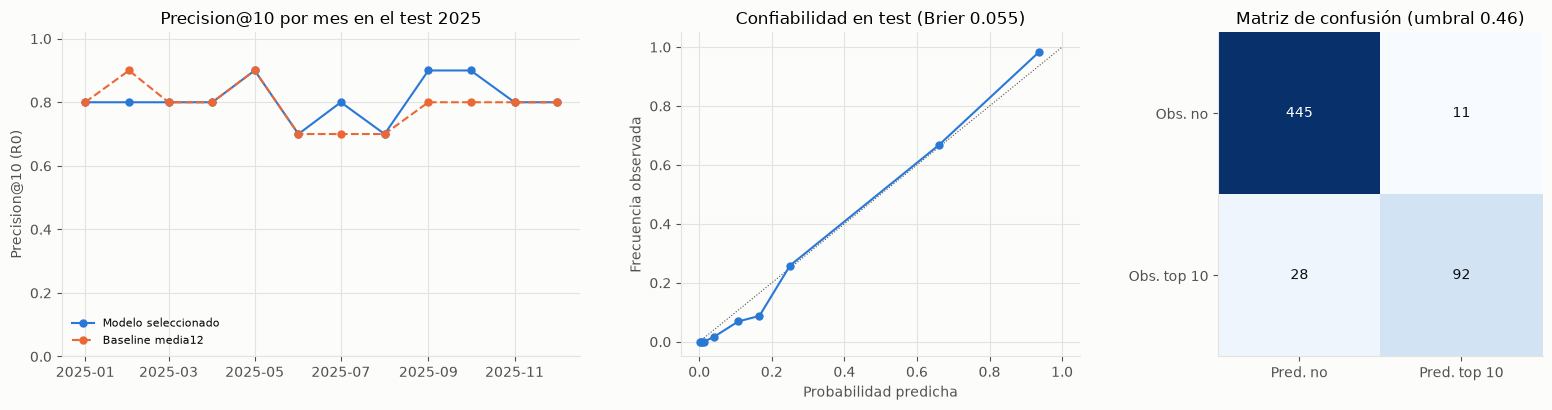

In [9]:
pt_t, pp_t = calibration_curve(T["top10_target"], T[sel_name], n_bins=10, strategy="quantile")
pm = pd.DataFrame({"modelo": Cl.precision_at_k(T, sel_name), "baseline": Cl.precision_at_k(T, bcol)})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
xm = pm.index.to_timestamp()
axes[0].plot(xm, pm["modelo"], color=CAT[0], marker="o", ms=5, label="Modelo seleccionado")
axes[0].plot(xm, pm["baseline"], color=CAT[1], marker="o", ms=5, ls="--", label=f"Baseline {frozen['mejor_baseline'].split(':')[1]}")
axes[0].set_ylim(0, 1.02); axes[0].set_ylabel("Precision@10 (R0)"); axes[0].set_title("Precision@10 por mes en el test 2025"); axes[0].legend(frameon=False, fontsize=8)
axes[1].plot([0, 1], [0, 1], color=INK2, lw=.8, ls=":"); axes[1].plot(pp_t, pt_t, color=CAT[0], marker="o", ms=5)
axes[1].set_xlabel("Probabilidad predicha"); axes[1].set_ylabel("Frecuencia observada"); axes[1].set_title(f"Confiabilidad en test (Brier {brier_score_loss(T['top10_target'], T[sel_name]):.3f})")
im = axes[2].imshow(cm, cmap="Blues"); axes[2].grid(False)
for (i, j), val in np.ndenumerate(cm): axes[2].text(j, i, int(val), ha="center", va="center", color=INK if val < cm.max() / 2 else "white")
axes[2].set_xticks([0, 1], ["Pred. no", "Pred. top 10"]); axes[2].set_yticks([0, 1], ["Obs. no", "Obs. top 10"])
axes[2].set_title(f"Matriz de confusión (umbral {frozen['umbral_F1']:.2f})")
fig.tight_layout(); fig.savefig(FIG / "test_p10_calibracion_confusion.png", dpi=150); plt.show()

**Lectura de la evaluación principal de 2025.**
- **Ranking.** P@10 de **0,808**, frente a 0,792 de la media de 12 meses: ΔP@10 = +0,017, es decir, **2 aciertos más en 120 selecciones** (10 por mes durante 12 meses).
- **Desempate.** La ventaja no depende del desempate: el intervalo pareado es [0,017; 0,017], porque los empates de 2025 no afectan la diferencia.
- **Entre meses.** El IC 95 % por bloques es [−0,017; +0,058] e **incluye el 0**. **No se confirma la mejora** (H4 no respaldada frente a la media de 12 meses). Frente a la persistencia, la ventaja es clara (0,808 frente a 0,746 de P@10 esperada; con el desempate R0, la persistencia obtiene 0,733).
- **Sin umbral.** PR-AUC 0,909 frente a 0,900, y ROC-AUC 0,966 frente a 0,963: diferencias mínimas.
- **Umbral congelado (0,46).** *Precision* 0,893, *recall* 0,767 y F1 0,825. La matriz de confusión tiene 92 verdaderos positivos, 11 falsos positivos y 28 falsos negativos.
- **Calibración.** Razonable en test: Brier 0,055 y curva de confiabilidad cercana a la diagonal. Pero es un solo año, y el modelo sobreestima la chance en los barrios de borde (0,146 frente a 0,102 observado; notebook 06, §5). Las probabilidades sirven como orientación, no como chances exactas (revisión independiente, R6).
- **Plazas inciertas.** Fuera del núcleo (Balvanera, Caballito, Flores, Palermo y Recoleta), el modelo acierta 39 de 60 selecciones (65 %) y el baseline 37 de 60 (62 %).

## 5. Interpretabilidad del modelo seleccionado

Las contribuciones se interpretan como **patrones predictivos, no como efectos causales**. Por la colinealidad entre variables (6 pares con Spearman > 0,95), se agregan **por familia**. El cálculo usa el modelo del ajuste final sobre las filas del test, solo para describir su comportamiento.

> **Qué hace la celda siguiente.** Calcula la importancia de las variables con SHAP y la agrupa por familia, porque las variables de historial son casi redundantes entre sí y su importancia individual se reparte de forma arbitraria.

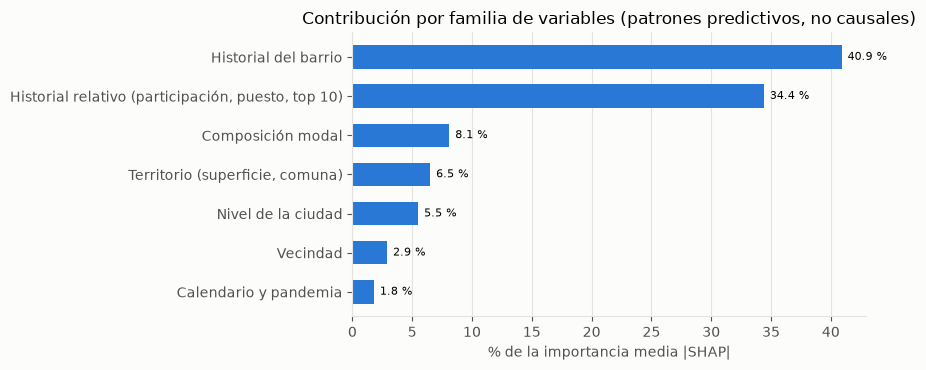

SHAP lineal exacto (log-odds), sobre variables estandarizadas
{'top10_freq12': 0.3364, 'rank_ma12': 0.2638, 'share_ma12': 0.2349, 'log_y_ma12': 0.2188, 'log_y_ma6': 0.2163, 'log_y_ma3': 0.1757, 'log_y_lag3': 0.1648, 'log_area_km2': 0.1612}


In [10]:
SEL = fitted[sel_name]; Xt = X.loc[te_fin]
if frozen["familia"] == "logit":
    # SHAP lineal exacto (independencia entre variables): φ_j = β_j · (z_j − E_train[z_j]) en log-odds
    pre, clf = SEL.named_steps["pre"], SEL.named_steps["clf"]
    Ztr = pre.transform(X.loc[R.train_mask_excluding_pandemia(X, tr_fin, frozen["params"]["excluir_pandemia"])])
    Zt = pre.transform(Xt); names = pre.get_feature_names_out()
    phi = (Zt - Ztr.mean(0)) * clf.coef_[0]
    metodo = "SHAP lineal exacto (log-odds), sobre variables estandarizadas"
else:
    import shap
    pre, clf = SEL.named_steps["pre"], SEL.named_steps["clf"]
    Zt = pre.transform(Xt); names = pre.get_feature_names_out()
    expl = shap.TreeExplainer(clf); phi = expl.shap_values(Zt)
    phi = phi[1] if isinstance(phi, list) else (phi[..., 1] if phi.ndim == 3 else phi)
    metodo = "SHAP TreeExplainer"
imp = pd.DataFrame({"variable": names, "mean_abs_shap": np.abs(phi).mean(0)})
imp["familia"] = imp["variable"].map(Cl.familia_de)
fam = imp.groupby("familia")["mean_abs_shap"].sum().sort_values(ascending=False)
fam_share = (fam / fam.sum() * 100).round(1)
imp.sort_values("mean_abs_shap", ascending=False).to_csv(TAB / "shap_variables.csv", index=False); fam_share.to_csv(TAB / "shap_familias.csv")
M["shap"] = {"metodo": metodo, "familias_pct": fam_share.to_dict(), "top8_variables": imp.nlargest(8, "mean_abs_shap").set_index("variable")["mean_abs_shap"].round(4).to_dict()}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(range(len(fam_share)), fam_share.values, color=CAT[0], height=.6); ax.set_yticks(range(len(fam_share)), fam_share.index); ax.invert_yaxis()
for i, v in enumerate(fam_share.values): ax.text(v + .5, i, f"{v:.1f} %", va="center", fontsize=8)
ax.set_xlabel("% de la importancia media |SHAP|"); ax.set_title("Contribución por familia de variables (patrones predictivos, no causales)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "shap_familias.png", dpi=150); plt.show()
print(metodo); print(M["shap"]["top8_variables"])

**Lectura (5).** El modelo se apoya en el **historial del barrio** (41 % de la importancia |SHAP|) y en el **historial relativo**: frecuencia en el top 10, puesto medio y participación (34 %). La composición modal (8 %), el territorio (6 %), el nivel de la ciudad (5 %), la vecindad (3 %) y el calendario (2 %) aportan poco. Las variables más influyentes son `top10_freq12`, `rank_ma12`, `share_ma12` y las medias de 12, 6 y 3 meses.

Esto es coherente con E6: el top 10 es sobre todo una **cuestión de persistencia**. Por eso el modelo apenas mejora a la media de 12 meses, que ya resume esa persistencia. Son patrones predictivos y no implican causas: por ejemplo, la composición modal no indica que más motos causen más siniestros.

## 6. Sensibilidad exploratoria a la latencia (gap = 1)

Se usa la misma configuración seleccionada, con particiones que respetan la disponibilidad de etiquetas (C13) y con el baseline recalculado con L = T−2.

In [11]:
X1 = XG[1]; f1_ = F.temporal_folds(X1); tr1, te1 = F.final_split(X1)
k, p = cfgs[sel_name]; rows = []
for nm, trm0, ev in [(fo["fold"], fo["train"], fo["val"]) for fo in f1_] + [("test 2025", tr1, te1)]:
    trm = R.train_mask_excluding_pandemia(X1, trm0, p["excluir_pandemia"])
    v = X1.loc[ev, ["barrio", "mes_objetivo", "y_target", "top10_target", bcol]].copy()
    v["p"] = Cl.make_model(k, p).fit(X1.loc[trm], X1.loc[trm, "top10_target"].astype(int)).predict_proba(X1.loc[ev])[:, 1]
    rows.append({"conjunto": nm, "P10e_modelo": Cl.expected_precision_at_k(v, "p").mean(), "P10e_baseline": Cl.expected_precision_at_k(v, bcol).mean()})
g1 = pd.DataFrame(rows); g1["delta"] = g1["P10e_modelo"] - g1["P10e_baseline"]
g1.to_csv(TAB / "sensibilidad_gap1.csv", index=False); M["gap1"] = g1.round(4).to_dict(orient="records"); g1.round(4)

,conjunto,P10e_modelo,P10e_baseline,delta
0,V2022,0.7694,0.7194,0.0500
1,V2023,0.8208,0.8083,0.0125
2,V2024,0.7861,0.7917,-0.0056
3,test 2025,0.8167,0.8083,0.0083


**Lectura (6).** Con información hasta T−2 y particiones que respetan la disponibilidad de etiquetas, la ventaja del modelo es inestable: +0,050 (V2022), +0,013 (V2023), −0,006 (V2024) y +0,008 (test). **No hay evidencia de una mejora sistemática** con mayor latencia. La conclusión principal se mantiene.

## 7. Registro

> **Qué hace la celda siguiente.** Guarda las cifras en `classification_metrics.json`, que usan el informe [docs/classification_report.md](../docs/classification_report.md) y el notebook 06.

In [12]:
(TAB / "classification_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado:", (TAB / "classification_metrics.json").relative_to(ROOT))

Guardado: reports\tables\04_classification\classification_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Respuesta a la pregunta.** El mejor modelo acierta algo más que el promedio de 12 meses (2 de 120 elecciones en 2025), pero la diferencia no es concluyente ni alcanza el umbral de relevancia fijado de antemano. La hipótesis H4 no se respalda frente a esa referencia.
- **Qué se aprendió.** La pertenencia al top 10 es sobre todo una cuestión de persistencia: el modelo resume el historial del barrio. Las demás familias de variables (composición por modo, territorio, calendario) pesan poco en el SHAP, que describe el modelo pero no mide cuánto agrega cada familia. La calibración es razonable en un solo año, con sobreestimación en el borde.
- **Límites.** Una sola temporada de prueba. La ventaja del modelo es inestable con un mes más de demora en la publicación. Las importancias SHAP describen el modelo, no causas.
- **Siguiente paso.** El notebook 05 cambia de pregunta: no cuántos siniestros, sino de qué tipo. El 06 evalúa estas estrategias como herramienta de priorización.